In [86]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.preprocessing import LabelEncoder
from mpl_toolkits.mplot3d import Axes3D
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report
sns.set_theme(style="darkgrid")

In [87]:
df= pd.read_csv('/content/drive/MyDrive/CSV/test.csv')

# Llene Los Espacios En Blanco

In [17]:
df.columns = df.columns.str.lower().str.replace(" ","_")
df

,unnamed:_0,id,gender,customer_type,age,type_of_travel,class,flight_distance,inflight_wifi_service,departure/arrival_time_convenient,...,inflight_entertainment,on-board_service,leg_room_service,baggage_handling,checkin_service,inflight_service,cleanliness,departure_delay_in_minutes,arrival_delay_in_minutes,satisfaction
0,0,19556,Female,Loyal Customer,52,Business travel,Eco,160,5,4,...,5,5,5,5,2,5,5,50,44.0,satisfied
1,1,90035,Female,Loyal Customer,36,Business travel,Business,2863,1,1,...,4,4,4,4,3,4,5,0,0.0,satisfied
2,2,12360,Male,disloyal Customer,20,Business travel,Eco,192,2,0,...,2,4,1,3,2,2,2,0,0.0,neutral or dissatisfied
3,3,77959,Male,Loyal Customer,44,Business travel,Business,3377,0,0,...,1,1,1,1,3,1,4,0,6.0,satisfied
4,4,36875,Female,Loyal Customer,49,Business travel,Eco,1182,2,3,...,2,2,2,2,4,2,4,0,20.0,satisfied
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25971,25971,78463,Male,disloyal Customer,34,Business travel,Business,526,3,3,...,4,3,2,4,4,5,4,0,0.0,neutral or dissatisfied
25972,25972,71167,Male,Loyal Customer,23,Business travel,Business,646,4,4,...,4,4,5,5,5,5,4,0,0.0,satisfied
25973,25973,37675,Female,Loyal Customer,17,Personal Travel,Eco,828,2,5,...,2,4,3,4,5,4,2,0,0.0,neutral or dissatisfied
25974,25974,90086,Male,Loyal Customer,14,Business travel,Business,1127,3,3,...,4,3,2,5,4,5,4,0,0.0,satisfied


# Datos No Nulos

In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25976 entries, 0 to 25975
Data columns (total 25 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   unnamed:_0                         25976 non-null  int64  
 1   id                                 25976 non-null  int64  
 2   gender                             25976 non-null  object 
 3   customer_type                      25976 non-null  object 
 4   age                                25976 non-null  int64  
 5   type_of_travel                     25976 non-null  object 
 6   class                              25976 non-null  object 
 7   flight_distance                    25976 non-null  int64  
 8   inflight_wifi_service              25976 non-null  int64  
 9   departure/arrival_time_convenient  25976 non-null  int64  
 10  ease_of_online_booking             25976 non-null  int64  
 11  gate_location                      25976 non-null  int

# Filas Duplicadas Eliminadas

In [19]:
df= df.drop_duplicates()

# Seleccionando A Los Puntajes Mas Bajos

In [20]:
servicio_wifi_malo= df[df['inflight_wifi_service']< 3]
servicio_wifi_malo.head()

,unnamed:_0,id,gender,customer_type,age,type_of_travel,class,flight_distance,inflight_wifi_service,departure/arrival_time_convenient,...,inflight_entertainment,on-board_service,leg_room_service,baggage_handling,checkin_service,inflight_service,cleanliness,departure_delay_in_minutes,arrival_delay_in_minutes,satisfaction
1,1,90035,Female,Loyal Customer,36,Business travel,Business,2863,1,1,...,4,4,4,4,3,4,5,0,0.0,satisfied
2,2,12360,Male,disloyal Customer,20,Business travel,Eco,192,2,0,...,2,4,1,3,2,2,2,0,0.0,neutral or dissatisfied
3,3,77959,Male,Loyal Customer,44,Business travel,Business,3377,0,0,...,1,1,1,1,3,1,4,0,6.0,satisfied
4,4,36875,Female,Loyal Customer,49,Business travel,Eco,1182,2,3,...,2,2,2,2,4,2,4,0,20.0,satisfied
7,7,97286,Female,Loyal Customer,43,Business travel,Business,2556,2,2,...,4,4,4,4,5,4,3,77,65.0,satisfied


## Conteo Por Genero De Los Que No Les Gusto El Wifi

In [21]:
servicio_wifi_malo_genero= servicio_wifi_malo["gender"].value_counts()
servicio_wifi_malo_genero

,count
gender,
Female,5969
Male,5822


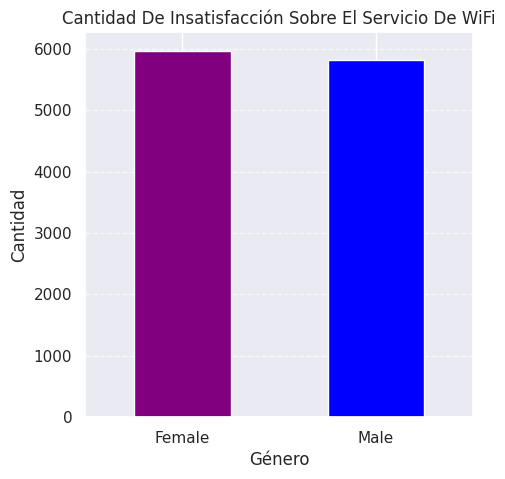

In [22]:
plt.figure(figsize=(5,5))
servicio_wifi_malo_genero.plot(kind='bar', color=['purple', 'blue'])
plt.title('Cantidad De Insatisfacción Sobre El Servicio De WiFi')
plt.xlabel('Género')
plt.ylabel('Cantidad')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

## Clasifiacion Por Edad Menor A 36





In [23]:
servicio_wifi_malo_edad= servicio_wifi_malo[servicio_wifi_malo["age"]< 36]
conteo_edad= servicio_wifi_malo_edad["age"].value_counts().sort_index()
conteo_edad.head()

,count
age,
7,56
8,88
9,80
10,70
11,88


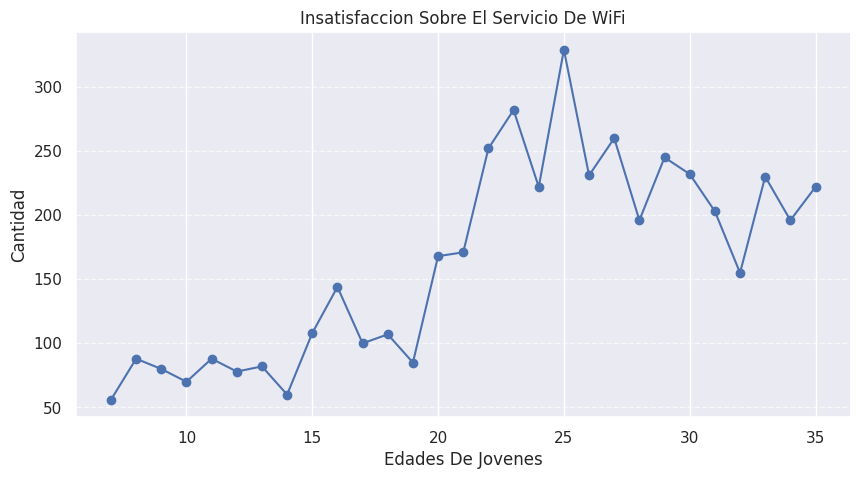

In [24]:
plt.figure(figsize=(10,5))
conteo_edad.plot(kind='line', marker='o')
plt.title('Insatisfaccion Sobre El Servicio De WiFi')
plt.xlabel('Edades De Jovenes')
plt.ylabel('Cantidad')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Clasifiacion Por Edad Mayor A 35

In [25]:
servicio_wifi_malo_edad= servicio_wifi_malo[servicio_wifi_malo["age"]> 35]
edad_conteo= servicio_wifi_malo_edad["age"].value_counts().sort_index()
edad_conteo.tail()

,count
age,
77,6
78,4
79,6
80,14
85,4


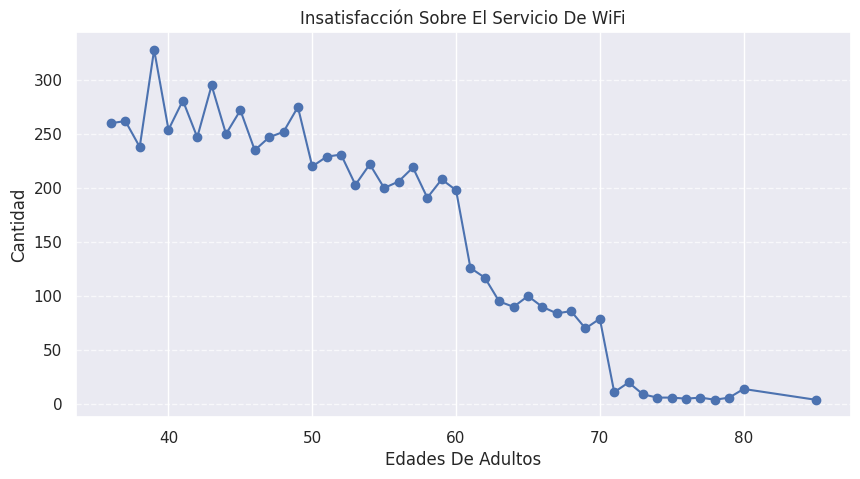

In [26]:
plt.figure(figsize=(10,5))
edad_conteo.plot(kind='line', marker='o')
plt.title('Insatisfacción Sobre El Servicio De WiFi')
plt.xlabel('Edades De Adultos')
plt.ylabel('Cantidad')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Cantidad De Edad De Personas

In [27]:
conteo_mayor= df[df["age"]> 70].shape[0]
conteo_mayor

208

In [28]:
conteo_menor= df[df['age']<= 69].shape[0]
conteo_menor

25619

# Grafica De Pastel Cantidad De Edades



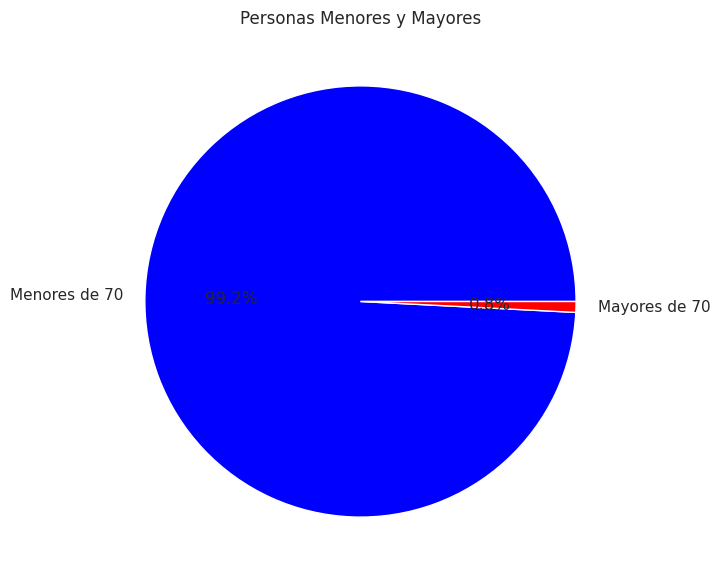

In [29]:
plt.figure(figsize=(7,7))
plt.pie([conteo_menor, conteo_mayor], labels=["Menores de 70", "Mayores de 70"], autopct="%1.1f%%", colors=["blue", "red"])
plt.title("Personas Menores y Mayores")
plt.show()

# Distancia Recorida Y Comodidad En El Espacio

In [30]:
espacio_distanica= df[['flight_distance', 'leg_room_service']]
espacio_distanica.describe().astype(int)

,flight_distance,leg_room_service
count,25976,25976
mean,1193,3
std,998,1
min,31,0
25%,414,2
50%,849,4
75%,1744,4
max,4983,5


# Grafica De Cajas y Bigotes

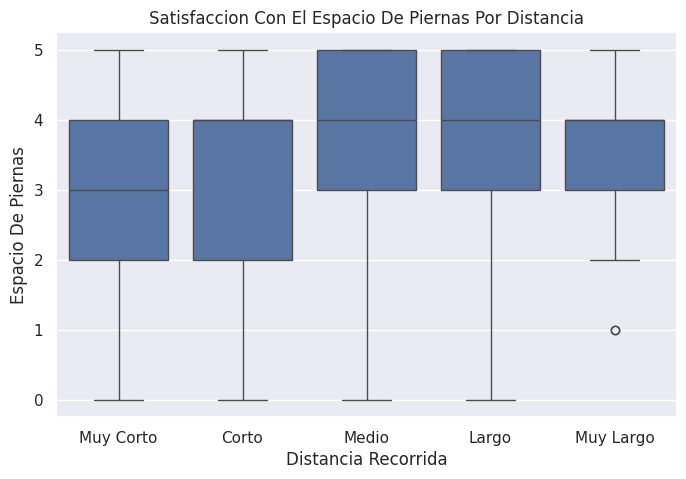

In [31]:
plt.figure(figsize=(8, 5))
bins = pd.cut(espacio_distanica['flight_distance'], bins=5, labels=["Muy Corto", "Corto", "Medio", "Largo", "Muy Largo"])
sns.boxplot(x=bins, y=espacio_distanica['leg_room_service'])
plt.title("Satisfaccion Con El Espacio De Piernas Por Distancia")
plt.xlabel("Distancia Recorrida")
plt.ylabel("Espacio De Piernas")
plt.show()

In [32]:
df.drop(columns=["id"], inplace= True)
df.head()

,unnamed:_0,gender,customer_type,age,type_of_travel,class,flight_distance,inflight_wifi_service,departure/arrival_time_convenient,ease_of_online_booking,...,inflight_entertainment,on-board_service,leg_room_service,baggage_handling,checkin_service,inflight_service,cleanliness,departure_delay_in_minutes,arrival_delay_in_minutes,satisfaction
0,0,Female,Loyal Customer,52,Business travel,Eco,160,5,4,3,...,5,5,5,5,2,5,5,50,44.0,satisfied
1,1,Female,Loyal Customer,36,Business travel,Business,2863,1,1,3,...,4,4,4,4,3,4,5,0,0.0,satisfied
2,2,Male,disloyal Customer,20,Business travel,Eco,192,2,0,2,...,2,4,1,3,2,2,2,0,0.0,neutral or dissatisfied
3,3,Male,Loyal Customer,44,Business travel,Business,3377,0,0,0,...,1,1,1,1,3,1,4,0,6.0,satisfied
4,4,Female,Loyal Customer,49,Business travel,Eco,1182,2,3,4,...,2,2,2,2,4,2,4,0,20.0,satisfied


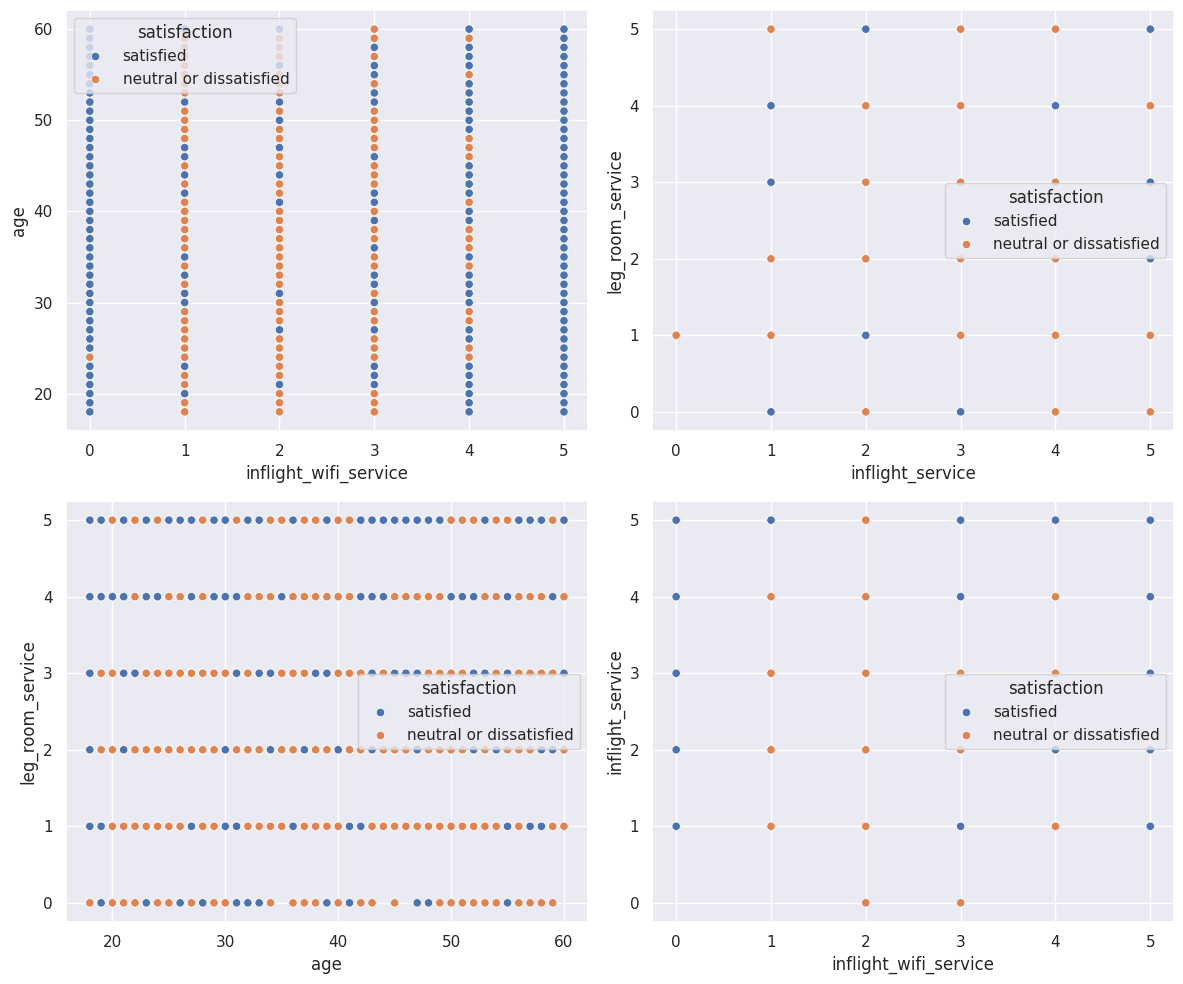

In [71]:
fig, axes= plt.subplots(2, 2, figsize=(12, 10))

sns.scatterplot(data= df, x='inflight_wifi_service', y='age', hue='satisfaction', ax= axes[0, 0])
sns.scatterplot(data= df, x='inflight_service', y='leg_room_service', hue='satisfaction', ax= axes[0, 1])
sns.scatterplot(data= df, x='age', y='leg_room_service', hue='satisfaction', ax= axes[1, 0])
sns.scatterplot(data= df, x='inflight_wifi_service', y='inflight_service', hue='satisfaction', ax= axes[1, 1])

plt.tight_layout()
plt.show()

                       inflight_wifi_service       age  inflight_service  \
inflight_wifi_service               1.000000  0.000827          0.108419   
age                                 0.000827  1.000000         -0.006842   
inflight_service                    0.108419 -0.006842          1.000000   
leg_room_service                    0.159699 -0.004451          0.373213   

                       leg_room_service  
inflight_wifi_service          0.159699  
age                           -0.004451  
inflight_service               0.373213  
leg_room_service               1.000000  


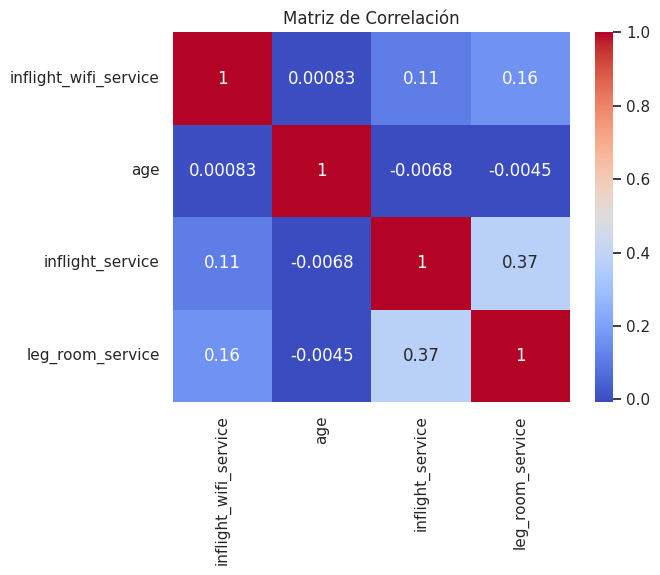

In [72]:
df_numeric= df[['inflight_wifi_service', 'age', 'inflight_service', 'leg_room_service']]

corr_matrix = df_numeric.corr()

print(corr_matrix)

sns.heatmap(corr_matrix, annot= True, cmap='coolwarm')
plt.title('Matriz de Correlación')
plt.show()

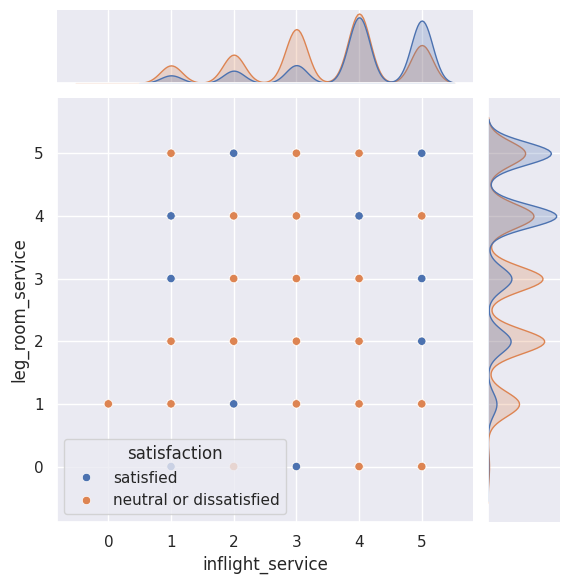

In [74]:
sns.jointplot(data=df, x = 'inflight_service', y='leg_room_service', hue='satisfaction')

In [88]:
print(df['satisfaction'].value_counts())

satisfaction
neutral or dissatisfied    14573
satisfied                  11403
Name: count, dtype: int64
